
# Análisis exploratorio de retrasos logísticos — Olist

## Objetivo general

Analizar el comportamiento de los retrasos en las entregas de Olist e identificar características potencialmente relacionadas con su ocurrencia.

## Objetivos específicos

1. Examinar la distribución de los retrasos y su comportamiento temporal.
2. Explorar la relación entre los retrasos y las características de clientes, vendedores y productos.
3. Identificar variables potencialmente útiles para construir un modelo predictivo.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ruta = Path("../data/raw")

pedidos = pd.read_csv(ruta / "olist_orders_dataset.csv")

In [2]:
pedidos["order_purchase_timestamp"] = pd.to_datetime(
    pedidos["order_purchase_timestamp"]
)

fechas = ["order_delivered_customer_date", "order_estimated_delivery_date"]

pedidos[fechas] = pedidos[fechas].apply(pd.to_datetime)

entregados = pedidos.loc[
    pedidos["order_status"].eq("delivered")
].dropna(subset=fechas).copy()

entregados["retraso"] = (
    entregados["order_delivered_customer_date"].dt.normalize()
    > entregados["order_estimated_delivery_date"].dt.normalize()
).astype(int)

entregados["retraso"].value_counts()

retraso
0    89936
1     6534
Name: count, dtype: int64

In [3]:
entregados["mes_compra"] = entregados["order_purchase_timestamp"].dt.to_period("M")

retrasos_mes = entregados.groupby("mes_compra")["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

retrasos_mes

,pedidos,retrasos,tasa_retraso
mes_compra,,,
2016-09,1,1,1.000000
2016-10,265,2,0.007547
2016-12,1,0,0.000000
2017-01,750,22,0.029333
2017-02,1653,49,0.029643
2017-03,2546,116,0.045562
2017-04,2303,151,0.065567
2017-05,3545,106,0.029901
2017-06,3135,95,0.030303


### Evolución mensual de los retrasos

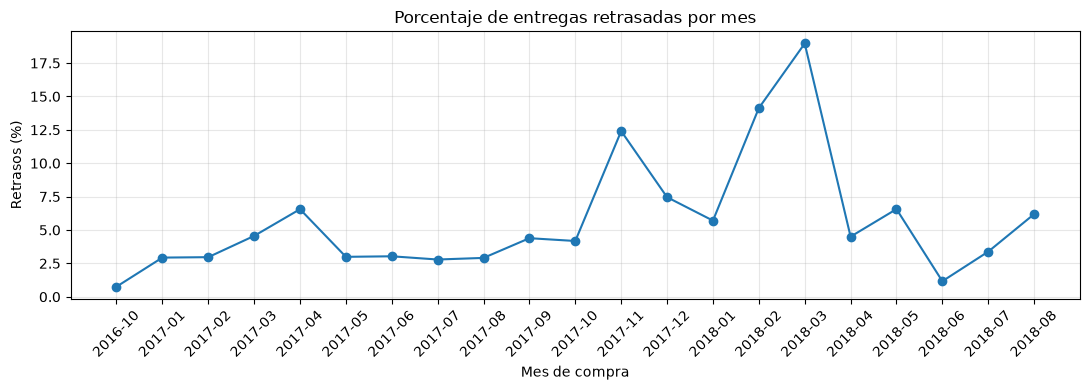

In [4]:
retrasos_grafico = retrasos_mes[retrasos_mes["pedidos"] >= 100]

plt.figure(figsize=(11, 4))
plt.plot(retrasos_grafico.index.astype(str),
         retrasos_grafico["tasa_retraso"] * 100,
         marker="o")

plt.title("Porcentaje de entregas retrasadas por mes")
plt.xlabel("Mes de compra")
plt.ylabel("Retrasos (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Volumen de pedidos y retrasos

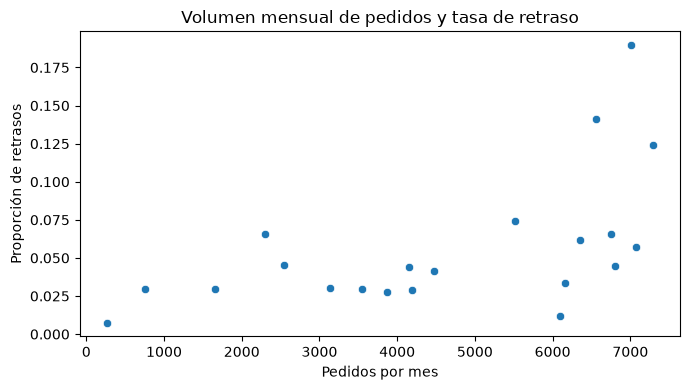

In [5]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=retrasos_grafico,
    x="pedidos",
    y="tasa_retraso"
)

plt.title("Volumen mensual de pedidos y tasa de retraso")
plt.xlabel("Pedidos por mes")
plt.ylabel("Proporción de retrasos")
plt.tight_layout()
plt.show()


In [6]:
retrasos_grafico["pedidos"].corr(retrasos_grafico["tasa_retraso"])

np.float64(0.5537895511442931)

### Retrasos por estado del cliente

In [7]:
clientes = pd.read_csv(ruta / "olist_customers_dataset.csv")

datos = entregados.merge(
    clientes[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

datos.shape

(96470, 11)

In [8]:
retrasos_estado = datos.groupby("customer_state")["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

retrasos_estado.sort_values("tasa_retraso", ascending=False)

,pedidos,retrasos,tasa_retraso
customer_state,,,
AL,397,85,0.214106
MA,717,125,0.174338
SE,335,51,0.152239
PI,476,66,0.138655
CE,1279,176,0.137608
RR,41,5,0.121951
BA,3256,396,0.121622
RJ,12350,1495,0.121053
PA,946,106,0.112051


### Comparación de retrasos por estado

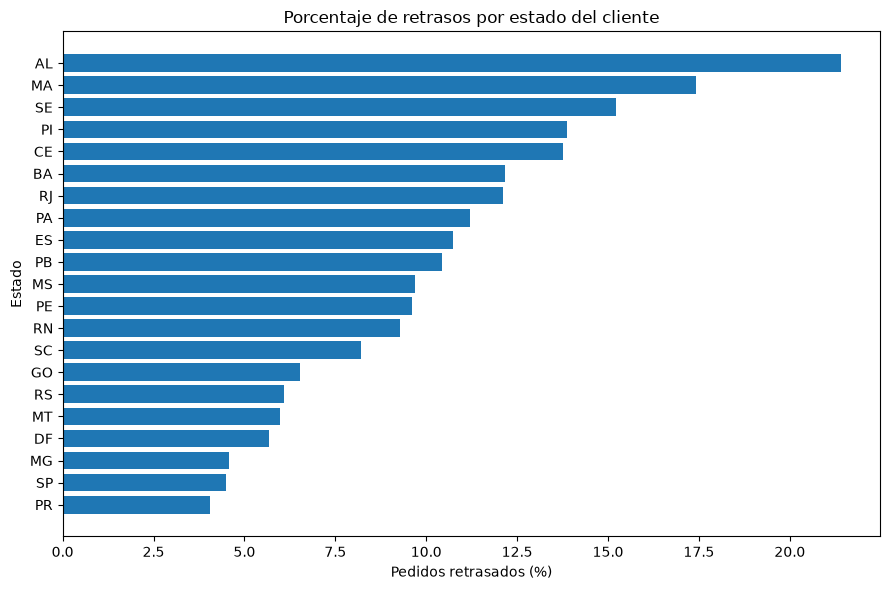

In [9]:
estados_grafico = retrasos_estado[retrasos_estado["pedidos"] >= 300]
estados_grafico = estados_grafico.sort_values("tasa_retraso")

plt.figure(figsize=(9, 6))
plt.barh(estados_grafico.index, estados_grafico["tasa_retraso"] * 100)

plt.title("Porcentaje de retrasos por estado del cliente")
plt.xlabel("Pedidos retrasados (%)")
plt.ylabel("Estado")
plt.tight_layout()
plt.show()

### Cantidad de artículos y retrasos

In [10]:
items = pd.read_csv(ruta / "olist_order_items_dataset.csv")

cantidad_items = items.groupby("order_id").size().rename("cantidad_items")

datos = datos.join(cantidad_items, on="order_id")

datos[["order_id", "cantidad_items", "retraso"]].head()

,order_id,cantidad_items,retraso
0,e481f51cbdc54678b7cc49136f2d6af7,1,0
1,53cdb2fc8bc7dce0b6741e2150273451,1,0
2,47770eb9100c2d0c44946d9cf07ec65d,1,0
3,949d5b44dbf5de918fe9c16f97b45f8a,1,0
4,ad21c59c0840e6cb83a9ceb5573f8159,1,0


In [11]:
datos.shape, datos["cantidad_items"].isna().sum()

((96470, 12), np.int64(0))

In [12]:
retrasos_items = datos.groupby("cantidad_items")["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

retrasos_items

,pedidos,retrasos,tasa_retraso
cantidad_items,,,
1,86835,6024,0.069373
2,7392,397,0.053707
3,1306,64,0.049005
4,495,23,0.046465
5,193,9,0.046632
6,191,16,0.083770
7,22,0,0.000000
8,8,0,0.000000
9,3,0,0.000000


In [13]:
datos["grupo_items"] = pd.cut(
    datos["cantidad_items"],
    bins=[0, 1, 2, float("inf")],
    labels=["1 artículo", "2 artículos", "3 o más"]
)

datos.groupby("grupo_items", observed=True)["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

,pedidos,retrasos,tasa_retraso
grupo_items,,,
1 artículo,86835,6024,0.069373
2 artículos,7392,397,0.053707
3 o más,2243,113,0.050379


### Peso de los productos y retrasos

In [14]:
productos = pd.read_csv(ruta / "olist_products_dataset.csv")

items_peso = items.merge(
    productos[["product_id", "product_weight_g"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

items_peso.shape

(112650, 8)

In [15]:
items_peso["product_weight_g"].isna().sum()

np.int64(18)

In [16]:
peso_pedido = items_peso.groupby("order_id")["product_weight_g"].sum(min_count=1)

peso_pedido.name = "peso_total_g"

datos = datos.join(peso_pedido, on="order_id")

datos[["order_id", "cantidad_items", "peso_total_g", "retraso"]].head()

,order_id,cantidad_items,peso_total_g,retraso
0,e481f51cbdc54678b7cc49136f2d6af7,1,500.0,0
1,53cdb2fc8bc7dce0b6741e2150273451,1,400.0,0
2,47770eb9100c2d0c44946d9cf07ec65d,1,420.0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,1,450.0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,1,250.0,0


In [17]:
pesos_faltantes = items_peso.loc[
    items_peso["product_weight_g"].isna(), "order_id"
].unique()

datos["order_id"].isin(pesos_faltantes).sum()

np.int64(16)

In [18]:
datos["peso_total_g"].describe()

count     96454.000000
mean       2386.868310
std        4770.109876
min           0.000000
25%         300.000000
50%         750.000000
75%        2050.000000
max      184400.000000
Name: peso_total_g, dtype: float64

In [19]:
datos["grupo_peso"] = pd.qcut(
    datos["peso_total_g"],
    q=4,
    duplicates="drop"
)

retrasos_peso = datos.groupby("grupo_peso", observed=True)["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

retrasos_peso

,pedidos,retrasos,tasa_retraso
grupo_peso,,,
"(-0.001, 300.0]",25205,1567,0.062170
"(300.0, 750.0]",23577,1584,0.067184
"(750.0, 2050.0]",23584,1592,0.067503
"(2050.0, 184400.0]",24088,1791,0.074352


### Ubicación de los vendedores

In [20]:
vendedores = pd.read_csv(ruta / "olist_sellers_dataset.csv")

items_vendedor = items.merge(
    vendedores[["seller_id", "seller_state"]],
    on="seller_id",
    how="left",
    validate="many_to_one"
)

items_vendedor.shape, items_vendedor["seller_state"].isna().sum()

((112650, 8), np.int64(0))

In [21]:
estados_por_pedido = items_vendedor.groupby("order_id")["seller_state"].nunique()

estados_por_pedido.value_counts().sort_index()

seller_state
1    98156
2      503
3        7
Name: count, dtype: int64

In [28]:
ubicaciones = items_vendedor.merge(
    datos[["order_id", "customer_state"]],
    on="order_id",
    validate="many_to_one"
)

ubicaciones.shape

(110189, 9)

vendedores ubicados en estados diferentes, crear una variable que identifique esa situación

In [23]:
ubicaciones["estado_diferente"] = (
    ubicaciones["seller_state"] != ubicaciones["customer_state"]
)

envios_estados = ubicaciones.groupby("order_id")["estado_diferente"].any()

datos = datos.join(
    envios_estados.rename("envio_entre_estados"),
    on="order_id"
)

In [24]:
datos.shape, datos["envio_entre_estados"].isna().sum()

((96470, 16), np.int64(0))

In [25]:
datos.groupby("envio_entre_estados")["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

,pedidos,retrasos,tasa_retraso
envio_entre_estados,,,
False,34575,1563,0.045206
True,61895,4971,0.080313


### Costo de envío y retrasos

In [26]:
costo_envio = items.groupby("order_id")["freight_value"].sum()

datos = datos.join(costo_envio.rename("costo_envio"), on="order_id")

datos["costo_envio"].describe()

count    96470.000000
mean        22.785798
std         21.559959
min          0.000000
25%         13.850000
50%         17.170000
75%         24.020000
max       1794.960000
Name: costo_envio, dtype: float64

In [27]:
datos["grupo_envio"] = pd.qcut(
    datos["costo_envio"],
    q=4,
    duplicates="drop"
)

datos.groupby("grupo_envio", observed=True)["retraso"].agg(
    pedidos="count",
    retrasos="sum",
    tasa_retraso="mean"
)

,pedidos,retrasos,tasa_retraso
grupo_envio,,,
"(-0.001, 13.85]",24153,1063,0.044011
"(13.85, 17.17]",24091,1686,0.069985
"(17.17, 24.02]",24112,1865,0.077347
"(24.02, 1794.96]",24114,1920,0.079622



## Conclusiones

1. **Comportamiento temporal:** La tasa de retrasos presentó variaciones entre meses, alcanzando el 18,96 % en marzo de 2018. Se identificó una correlación positiva moderada (0,55) entre el volumen mensual de pedidos y la tasa de retraso.

2. **Características geográficas y logísticas:** Se observaron diferencias entre estados de Brasil. Los pedidos con vendedores ubicados en estados diferentes al del cliente presentaron una tasa de retraso del 8,03 %, frente al 4,52 % de los pedidos cuyos vendedores pertenecían al mismo estado.

3. **Características de los productos:** Los pedidos de mayor peso presentaron tasas de retraso ligeramente superiores. En cambio, la cantidad de artículos no mostró una relación creciente con los retrasos.

4. **Costo de envío:** La tasa de retrasos aumentó del 4,40 % en el grupo de menor costo al 7,96 % en el de mayor costo.

5. **Variables candidatas:** El mes de compra, el estado del cliente, el peso total, la cantidad de artículos, el costo de envío y la relación geográfica entre cliente y vendedores constituyen características potencialmente útiles para el modelado. Su contribución predictiva deberá evaluarse posteriormente.
